In [1]:
import numpy as np
from pathlib import Path
from PIL import Image

SEG_IMG_DIR = Path("../data/raw/segmentation/data/data/images")
SEG_MASK_DIR = Path("../data/raw/segmentation/data/data/masks")

sample_mask = Image.open(sorted(SEG_MASK_DIR.glob("*"))[0])
mask_array = np.array(sample_mask)

print(f"Mask shape: {mask_array.shape}")
print(f"Mask dtype: {mask_array.dtype}")
print(f"Unique pixel values (first 20): {np.unique(mask_array.reshape(-1, mask_array.shape[-1]) if mask_array.ndim == 3 else mask_array, axis=0)[:20]}")

Mask shape: (235, 326)
Mask dtype: uint8
Unique pixel values (first 20): [[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [2]:
print(f"Mask shape: {mask_array.shape}")
print(f"Mask dtype: {mask_array.dtype}")
print(f"Min value: {mask_array.min()}, Max value: {mask_array.max()}")
print(f"Unique pixel values: {np.unique(mask_array)}")

Mask shape: (235, 326)
Mask dtype: uint8
Min value: 0, Max value: 1
Unique pixel values: [0 1]


In [3]:
from collections import Counter

mask_files = sorted(SEG_MASK_DIR.glob("*"))
mode_counter = Counter()
shape_counter = Counter()

for mp in mask_files:
    m = Image.open(mp)
    mode_counter[m.mode] += 1
    shape_counter[np.array(m).shape] += 1

print(f"Total mask files: {len(mask_files)}")
print(f"PIL modes found: {dict(mode_counter)}")
print(f"Array shapes found: {dict(shape_counter)}")

Total mask files: 588
PIL modes found: {'P': 311, 'RGB': 277}
Array shapes found: {(235, 326): 1, (234, 326): 1, (236, 350): 1, (423, 640): 1, (1440, 2160): 1, (600, 800): 10, (1024, 823): 1, (267, 199): 1, (275, 400): 1, (384, 550): 1, (643, 960): 1, (566, 850): 1, (261, 382): 1, (640, 480): 3, (300, 400): 6, (677, 1024): 1, (1024, 677): 1, (360, 480): 1, (205, 279): 1, (409, 228): 1, (1286, 613): 1, (2448, 3264): 1, (329, 198): 1, (375, 250): 1, (398, 600): 1, (552, 736): 3, (768, 1024): 5, (1296, 1600): 1, (334, 500): 1, (956, 1532): 1, (436, 1024): 1, (231, 390): 1, (216, 325): 1, (426, 640): 1, (1024, 1023): 2, (1486, 1024): 1, (468, 675): 1, (526, 600): 1, (1063, 1600): 1, (486, 394): 1, (272, 600): 2, (265, 355): 1, (451, 389): 1, (265, 205): 1, (598, 595): 1, (427, 640): 2, (589, 420): 1, (3120, 4160): 1, (336, 300): 1, (670, 502): 1, (324, 432): 1, (231, 432): 1, (800, 600): 3, (443, 590): 1, (314, 236): 2, (400, 300): 2, (642, 960): 1, (640, 478): 1, (150, 200): 1, (1200, 160

In [4]:
p_mode_issues = []
for mp in mask_files:
    m = Image.open(mp)
    if m.mode == 'P':
        arr = np.array(m)
        uniques = set(np.unique(arr).tolist())
        if not uniques.issubset({0, 1}):
            p_mode_issues.append((mp.name, uniques))

print(f"P-mode masks with unexpected values: {len(p_mode_issues)} out of 311")
if p_mode_issues:
    print(p_mode_issues[:10])

P-mode masks with unexpected values: 0 out of 311


In [5]:
rgb_files = [mp for mp in mask_files if Image.open(mp).mode == 'RGB'][:5]

for mp in rgb_files:
    arr = np.array(Image.open(mp))
    colors, counts = np.unique(arr.reshape(-1, 3), axis=0, return_counts=True)
    top5 = colors[np.argsort(-counts)][:5]
    print(f"{mp.name}: {len(colors)} unique colors, top 5 most common: {top5.tolist()}")

00311.png: 111 unique colors, top 5 most common: [[0, 0, 0], [128, 0, 0], [110, 0, 0], [10, 0, 0], [73, 0, 0]]
00312.png: 91 unique colors, top 5 most common: [[0, 0, 0], [128, 0, 0], [48, 0, 0], [80, 0, 0], [112, 0, 0]]
00313.png: 129 unique colors, top 5 most common: [[0, 0, 0], [128, 0, 0], [3, 0, 0], [1, 0, 0], [23, 0, 0]]
00314.png: 128 unique colors, top 5 most common: [[0, 0, 0], [128, 0, 0], [44, 0, 0], [4, 0, 0], [108, 0, 0]]
00315.png: 37 unique colors, top 5 most common: [[0, 0, 0], [128, 0, 0], [96, 0, 0], [32, 0, 0], [30, 0, 0]]


In [6]:
import numpy as np
from pathlib import Path
from PIL import Image

SEG_IMG_DIR = Path("../data/raw/segmentation/data/data/images")
SEG_MASK_DIR = Path("../data/raw/segmentation/data/data/masks")
OUT_IMG_DIR = Path("../data/processed/segmentation/images")
OUT_MASK_DIR = Path("../data/processed/segmentation/masks")
OUT_IMG_DIR.mkdir(parents=True, exist_ok=True)
OUT_MASK_DIR.mkdir(parents=True, exist_ok=True)

TARGET_SIZE = (128, 128)

def load_binary_mask(path):
    m = Image.open(path)
    if m.mode == 'P':
        arr = np.array(m)  # already {0, 1}
    elif m.mode == 'RGB':
        r = np.array(m)[:, :, 0]
        arr = (r > 64).astype(np.uint8)  # midpoint between 0 and 128
    else:
        raise ValueError(f"Unexpected mode {m.mode} in {path.name}")
    return arr

img_files = sorted(SEG_IMG_DIR.glob("*"))
mask_files = sorted(SEG_MASK_DIR.glob("*"))
assert len(img_files) == len(mask_files), "Image/mask count mismatch"

for img_path, mask_path in zip(img_files, mask_files):
    assert img_path.stem == mask_path.stem, f"Filename mismatch: {img_path.name} vs {mask_path.name}"

    mask_arr = load_binary_mask(mask_path)
    mask_img = Image.fromarray(mask_arr * 255)  # 0/1 -> 0/255 so it's actually viewable as an image
    mask_img = mask_img.resize(TARGET_SIZE, resample=Image.NEAREST)  # NEAREST is deliberate, see note below
    mask_img.save(OUT_MASK_DIR / f"{img_path.stem}.png")

    img = Image.open(img_path).convert("RGB")
    img = img.resize(TARGET_SIZE, resample=Image.BILINEAR)
    img.save(OUT_IMG_DIR / f"{img_path.stem}.png")

print(f"Processed {len(img_files)} image/mask pairs into {OUT_IMG_DIR} and {OUT_MASK_DIR}")

Processed 588 image/mask pairs into ..\data\processed\segmentation\images and ..\data\processed\segmentation\masks


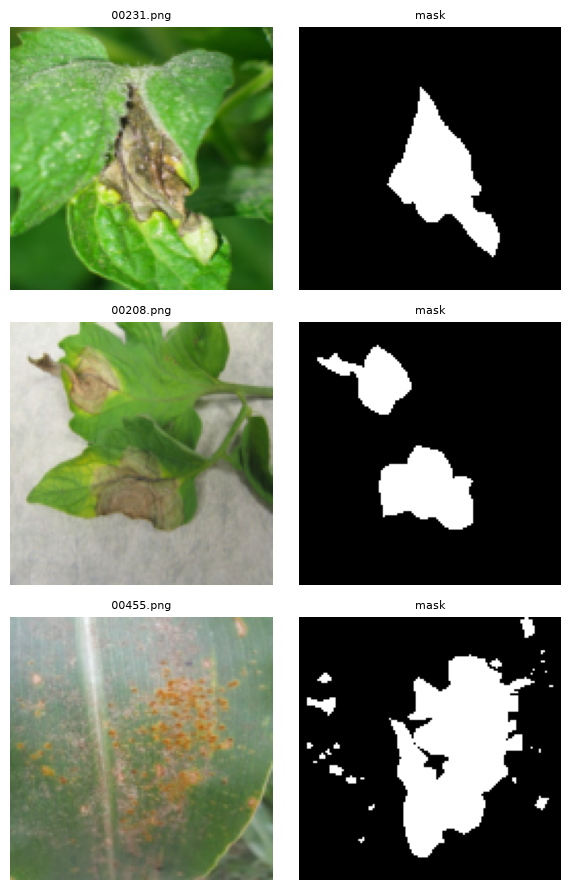

In [7]:
import matplotlib.pyplot as plt
import random

processed_imgs = sorted(OUT_IMG_DIR.glob("*"))
processed_masks = sorted(OUT_MASK_DIR.glob("*"))

fig, axes = plt.subplots(3, 2, figsize=(6, 9))
sample_idxs = random.sample(range(len(processed_imgs)), 3)

for row, idx in enumerate(sample_idxs):
    img = Image.open(processed_imgs[idx])
    mask = Image.open(processed_masks[idx])
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(processed_imgs[idx].name, fontsize=8)
    axes[row, 0].axis("off")
    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title("mask", fontsize=8)
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [8]:
import tensorflow as tf
import numpy as np
from pathlib import Path

IMG_DIR = Path("../data/processed/segmentation/images")
MASK_DIR = Path("../data/processed/segmentation/masks")

img_paths = sorted([str(p) for p in IMG_DIR.glob("*.png")])
mask_paths = sorted([str(p) for p in MASK_DIR.glob("*.png")])
assert len(img_paths) == len(mask_paths), "Image/mask count mismatch"

rng = np.random.default_rng(42)
idx = rng.permutation(len(img_paths))
img_paths = np.array(img_paths)[idx]
mask_paths = np.array(mask_paths)[idx]

n = len(img_paths)
n_test = int(n * 0.15)
n_val = int(n * 0.15)

test_img, test_mask = img_paths[:n_test], mask_paths[:n_test]
val_img, val_mask = img_paths[n_test:n_test+n_val], mask_paths[n_test:n_test+n_val]
train_img, train_mask = img_paths[n_test+n_val:], mask_paths[n_test+n_val:]

print(f"Train: {len(train_img)}, Val: {len(val_img)}, Test: {len(test_img)}")

Train: 412, Val: 88, Test: 88


In [9]:
IMG_SIZE = (128, 128)

def load_image_mask(img_path, mask_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.image.resize(mask, IMG_SIZE, method="nearest")
    mask = tf.cast(mask > 127, tf.float32)
    return img, mask

def augment_pair(img, mask):
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_left_right(img)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_up_down(img)
        mask = tf.image.flip_up_down(mask)
    return img, mask

def make_dataset(imgs, masks, batch_size=16, shuffle=False, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((imgs, masks))
    ds = ds.map(load_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.map(augment_pair, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=len(imgs))
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds_seg = make_dataset(train_img, train_mask, shuffle=True, augment=True)
val_ds_seg = make_dataset(val_img, val_mask)
test_ds_seg = make_dataset(test_img, test_mask)

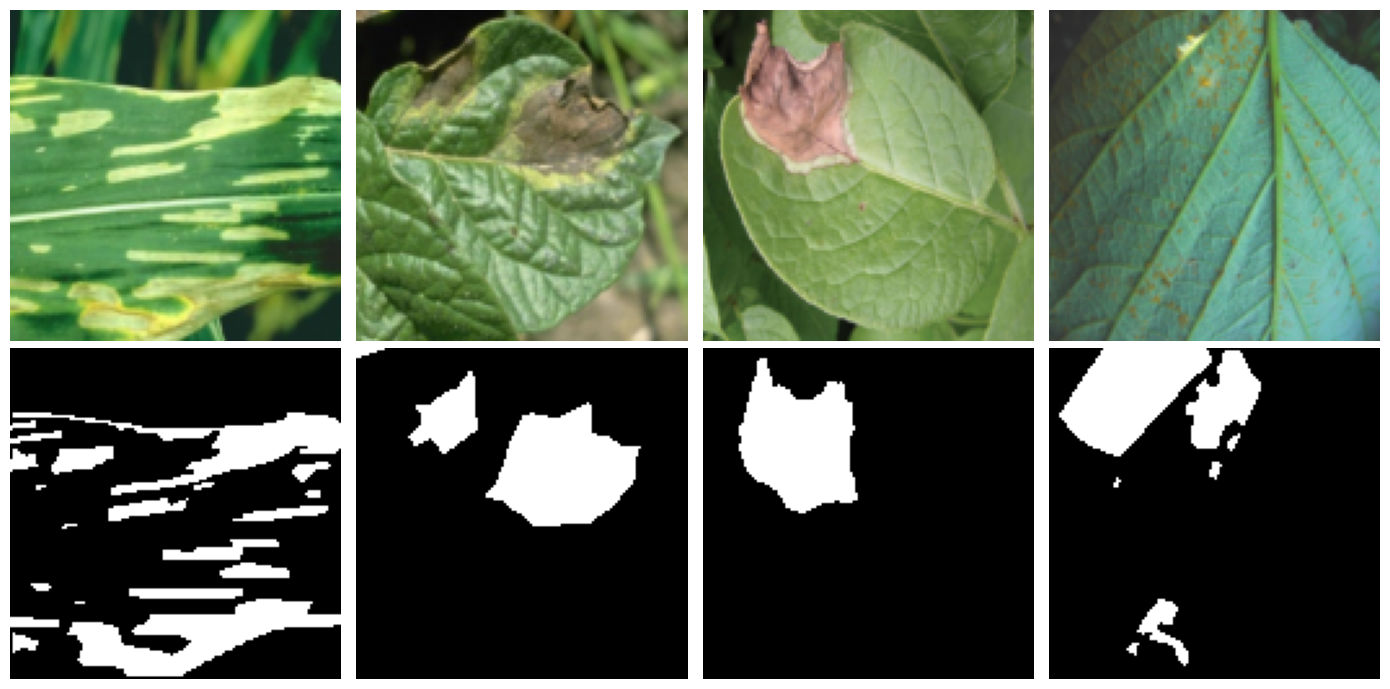

In [12]:
import matplotlib.pyplot as plt

for imgs, masks in train_ds_seg.take(1):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for i in range(4):
        axes[0, i].imshow(imgs[i])
        axes[0, i].axis("off")
        axes[1, i].imshow(masks[i, :, :, 0], cmap="gray")
        axes[1, i].axis("off")
    plt.tight_layout()
    plt.show()

In [13]:
def conv_block(x, filters, dropout_rate=0.0):
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    if dropout_rate > 0:
        x = tf.keras.layers.Dropout(dropout_rate)(x)
    return x

def build_unet(input_shape=(128, 128, 3)):
    inputs = tf.keras.Input(shape=input_shape)

    # Encoder — each level halves resolution, doubles filter depth
    c1 = conv_block(inputs, 32)
    p1 = tf.keras.layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 64)
    p2 = tf.keras.layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 128)
    p3 = tf.keras.layers.MaxPooling2D()(c3)

    # Bottleneck — deepest point, most compressed representation
    b = conv_block(p3, 256, dropout_rate=0.3)

    # Decoder — each level upsamples, then concatenates the matching encoder skip
    u3 = tf.keras.layers.Conv2DTranspose(128, 2, strides=2, padding="same")(b)
    u3 = tf.keras.layers.Concatenate()([u3, c3])
    d3 = conv_block(u3, 128)

    u2 = tf.keras.layers.Conv2DTranspose(64, 2, strides=2, padding="same")(d3)
    u2 = tf.keras.layers.Concatenate()([u2, c2])
    d2 = conv_block(u2, 64)

    u1 = tf.keras.layers.Conv2DTranspose(32, 2, strides=2, padding="same")(d2)
    u1 = tf.keras.layers.Concatenate()([u1, c1])
    d1 = conv_block(u1, 32)

    outputs = tf.keras.layers.Conv2D(1, 1, activation="sigmoid")(d1)
    return tf.keras.Model(inputs, outputs, name="unet_severity")

unet = build_unet()
unet.summary()

Model: "unet_severity"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 128, 128, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 128, 128, 32)      │             896 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 128, 128, 32)      │             128 │ conv2d[0][0]               │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 128, 128, 32)      │           9,248 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 128, 128, 32)      │             128 │ conv2d_1[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 64, 64, 32)        │               0 │ batch_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_2 (Conv2D)             │ (None, 64, 64, 64)        │          18,496 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_2         │ (None, 64, 64, 64)        │             256 │ conv2d_2[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_3 (Conv2D)             │ (None, 64, 64, 64)        │          36,928 │ batch_normalization_2[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_3         │ (None, 64, 64, 64)        │             256 │ conv2d_3[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d_1               │ (None, 32, 32, 64)        │               0 │ batch_normalization_3[0][… │
│ (MaxPooling2D)                │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_4 (Conv2D)             │ (None, 32, 32, 128)       │          73,856 │ max_pooling2d_1[0][0]      │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_4         │ (None, 32, 32, 128)       │             512 │ conv2d_4[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_5 (Conv2D)             │ (None, 32, 32, 128)       │         147,584 │ batch_normalization_4[0][… │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 1,931,233 (7.37 MB)

 Trainable params: 1,928,417 (7.36 MB)

 Non-trainable params: 2,816 (11.00 KB)

In [18]:
def dice_loss(y_true, y_pred, smooth=1e-6):
    axes = [1, 2, 3]
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    union = tf.reduce_sum(y_true, axis=axes) + tf.reduce_sum(y_pred, axis=axes)
    dice = (2. * intersection + smooth) / (union + smooth)
    return 1 - tf.reduce_mean(dice)

def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + dice_loss(y_true, y_pred)

def iou_metric(y_true, y_pred, threshold=0.5, smooth=1e-6):
    y_pred_bin = tf.cast(y_pred > threshold, tf.float32)
    axes = [1, 2, 3]
    intersection = tf.reduce_sum(y_true * y_pred_bin, axis=axes)
    union = tf.reduce_sum(y_true, axis=axes) + tf.reduce_sum(y_pred_bin, axis=axes) - intersection
    iou = (intersection + smooth) / (union + smooth)
    return tf.reduce_mean(iou)

In [15]:
checkpoint_path_local = "../models/unet_severity.keras"

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    checkpoint_path_local, save_best_only=True, monitor="val_iou_metric", mode="max"
)
early_stop_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_iou_metric", mode="max", patience=8, restore_best_weights=True
)

history_unet = unet.fit(
    train_ds_seg,
    validation_data=val_ds_seg,
    epochs=50,
    callbacks=[checkpoint_cb, early_stop_cb]
)

Epoch 1/50


C:\Users\markp\OneDrive\Desktop\agrisense-ai\ml\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


26/26 ━━━━━━━━━━━━━━━━━━━━ 103s 3s/step - iou_metric: 0.2842 - loss: 1.3230 - val_iou_metric: 0.1711 - val_loss: 1.3921
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 82s 3s/step - iou_metric: 0.3339 - loss: 1.2007 - val_iou_metric: 0.1712 - val_loss: 1.9260
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 74s 3s/step - iou_metric: 0.3695 - loss: 1.1081 - val_iou_metric: 0.3035 - val_loss: 1.3382
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - iou_metric: 0.3954 - loss: 1.0394 - val_iou_metric: 0.1128 - val_loss: 1.7128
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - iou_metric: 0.4122 - loss: 0.9690 - val_iou_metric: 0.1682 - val_loss: 5.4011
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - iou_metric: 0.4302 - loss: 0.9083 - val_iou_metric: 0.1633 - val_loss: 14.4330
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - iou_metric: 0.4405 - loss: 0.8558 - val_iou_metric: 2.7744e-11 - val_loss: 1.3758
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - iou_metric: 0.4281 - loss: 0.8447 - val_iou

In [19]:
diseased_fractions_all = {}
for img_path, mask_path in zip(img_paths, mask_paths):
    mask = np.array(tf.io.decode_png(tf.io.read_file(mask_path), channels=1))
    diseased_fractions_all[img_path] = (mask > 127).mean()

keep_mask = np.array([diseased_fractions_all[p] >= 0.01 for p in img_paths])
img_paths_clean = img_paths[keep_mask]
mask_paths_clean = mask_paths[keep_mask]
print(f"Kept {len(img_paths_clean)} of {len(img_paths)} pairs")

# Re-split with the cleaned set — same logic as before, applied fresh
rng = np.random.default_rng(42)
idx = rng.permutation(len(img_paths_clean))
img_paths_clean = img_paths_clean[idx]
mask_paths_clean = mask_paths_clean[idx]

n = len(img_paths_clean)
n_test = int(n * 0.15)
n_val = int(n * 0.15)

test_img, test_mask = img_paths_clean[:n_test], mask_paths_clean[:n_test]
val_img, val_mask = img_paths_clean[n_test:n_test+n_val], mask_paths_clean[n_test:n_test+n_val]
train_img, train_mask = img_paths_clean[n_test+n_val:], mask_paths_clean[n_test+n_val:]

train_ds_seg = make_dataset(train_img, train_mask, shuffle=True, augment=True)
val_ds_seg = make_dataset(val_img, val_mask)
test_ds_seg = make_dataset(test_img, test_mask)

Kept 569 of 588 pairs


In [21]:
unet = build_unet()
unet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
    loss=bce_dice_loss,
    metrics=[iou_metric]
)

reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_iou_metric", mode="max", factor=0.5, patience=4, min_lr=1e-6
)

history_unet = unet.fit(
    train_ds_seg,
    validation_data=val_ds_seg,
    epochs=50,
    callbacks=[checkpoint_cb, early_stop_cb, reduce_lr_cb]
)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 100s 3s/step - iou_metric: 0.2907 - loss: 1.3610 - val_iou_metric: 0.2346 - val_loss: 1.4410 - learning_rate: 5.0000e-04
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 79s 3s/step - iou_metric: 0.3730 - loss: 1.2305 - val_iou_metric: 2.5261e-05 - val_loss: 1.3771 - learning_rate: 5.0000e-04
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 92s 4s/step - iou_metric: 0.3964 - loss: 1.1555 - val_iou_metric: 7.3195e-10 - val_loss: 1.3223 - learning_rate: 5.0000e-04
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 73s 3s/step - iou_metric: 0.4157 - loss: 1.1164 - val_iou_metric: 0.0016 - val_loss: 1.2837 - learning_rate: 5.0000e-04
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 64s 3s/step - iou_metric: 0.4319 - loss: 1.0475 - val_iou_metric: 2.1292e-05 - val_loss: 1.2828 - learning_rate: 5.0000e-04
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 65s 3s/step - iou_metric: 0.4493 - loss: 0.9877 - val_iou_metric: 7.3195e-10 - val_loss: 1.3074 - learning_rate: 2.5000e-04
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━

In [22]:
def build_unet_mobilenet(input_shape=(128, 128, 3)):
    base_model = tf.keras.applications.MobileNetV2(input_shape=input_shape, include_top=False)

    # Layer names chosen so their spatial resolutions exactly match the decoder's upsampling steps
    skip_names = [
        'block_1_expand_relu',   # 64x64
        'block_3_expand_relu',   # 32x32
        'block_6_expand_relu',   # 16x16
        'block_13_expand_relu',  # 8x8
        'block_16_project',      # 4x4 — deepest, used as the bottleneck
    ]
    skip_outputs = [base_model.get_layer(name).output for name in skip_names]

    down_stack = tf.keras.Model(inputs=base_model.input, outputs=skip_outputs)
    down_stack.trainable = False  # frozen first pass — same principle as Stage 2

    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
    s1, s2, s3, s4, bottleneck = down_stack(x)

    def upsample_block(x, skip, filters):
        x = tf.keras.layers.Conv2DTranspose(filters, 3, strides=2, padding="same")(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.ReLU()(x)
        x = tf.keras.layers.Concatenate()([x, skip])
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = tf.keras.layers.BatchNormalization()(x)
        return x

    x = upsample_block(bottleneck, s4, 512)   # 4x4 -> 8x8
    x = upsample_block(x, s3, 256)            # 8x8 -> 16x16
    x = upsample_block(x, s2, 128)            # 16x16 -> 32x32
    x = upsample_block(x, s1, 64)             # 32x32 -> 64x64

    x = tf.keras.layers.Conv2DTranspose(32, 3, strides=2, padding="same")(x)  # 64x64 -> 128x128
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)

    outputs = tf.keras.layers.Conv2D(1, 1, activation="sigmoid")(x)
    return tf.keras.Model(inputs, outputs, name="unet_mobilenet_severity")

unet2 = build_unet_mobilenet()
unet2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=bce_dice_loss,
    metrics=[iou_metric]
)
unet2.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "unet_mobilenet_severity"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)    │ (None, 128, 128, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ true_divide (TrueDivide)      │ (None, 128, 128, 3)       │               0 │ input_layer_4[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ subtract (Subtract)           │ (None, 128, 128, 3)       │               0 │ true_divide[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ functional (Functional)       │ [(None, 64, 64, 96),      │       1,841,984 │ subtract[0][0]             │
│                               │ (None, 32, 32, 144),      │                 │                            │
│                               │ (None, 16, 16, 192),      │                 │                            │
│                               │ (None, 8, 8, 576), (None, │                 │                            │
│                               │ 4, 4, 320)]               │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_transpose_9            │ (None, 8, 8, 512)         │       1,475,072 │ functional[0][4]           │
│ (Conv2DTranspose)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_42        │ (None, 8, 8, 512)         │           2,048 │ conv2d_transpose_9[0][0]   │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ re_lu (ReLU)                  │ (None, 8, 8, 512)         │               0 │ batch_normalization_42[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ concatenate_9 (Concatenate)   │ (None, 8, 8, 1088)        │               0 │ re_lu[0][0],               │
│                               │                           │                 │ functional[0][3]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_45 (Conv2D)            │ (None, 8, 8, 512)         │       5,014,016 │ concatenate_9[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_43        │ (None, 8, 8, 512)         │           2,048 │ conv2d_45[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_transpose_10           │ (None, 16, 16, 256)       │       1,179,904 │ batch_normalization_43[0]… │
│ (Conv2DTranspose)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_44        │ (None, 16, 16, 256)       │           1,024 │ conv2d_transpose_10[0][0]  │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 11,344,257 (43.27 MB)

 Trainable params: 9,498,369 (36.23 MB)

 Non-trainable params: 1,845,888 (7.04 MB)

In [23]:
checkpoint_path_v2 = "../models/unet_mobilenet_severity.keras"

checkpoint_cb2 = tf.keras.callbacks.ModelCheckpoint(
    checkpoint_path_v2, save_best_only=True, monitor="val_iou_metric", mode="max"
)
early_stop_cb2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_iou_metric", mode="max", patience=8, restore_best_weights=True
)
reduce_lr_cb2 = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_iou_metric", mode="max", factor=0.5, patience=4, min_lr=1e-6
)

history_unet2 = unet2.fit(
    train_ds_seg,
    validation_data=val_ds_seg,
    epochs=50,
    callbacks=[checkpoint_cb2, early_stop_cb2, reduce_lr_cb2]
)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 58s 2s/step - iou_metric: 0.2178 - loss: 1.2775 - val_iou_metric: 0.0016 - val_loss: 2.0355 - learning_rate: 0.0010
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - iou_metric: 0.2275 - loss: 1.1671 - val_iou_metric: 0.0022 - val_loss: 1.5479 - learning_rate: 0.0010
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - iou_metric: 0.2217 - loss: 1.1462 - val_iou_metric: 7.7596e-04 - val_loss: 1.5358 - learning_rate: 0.0010
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - iou_metric: 0.2356 - loss: 1.1264 - val_iou_metric: 7.3195e-10 - val_loss: 1.7534 - learning_rate: 0.0010
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - iou_metric: 0.2431 - loss: 1.1131 - val_iou_metric: 7.3195e-10 - val_loss: 1.4368 - learning_rate: 0.0010
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - iou_metric: 0.2606 - loss: 1.0915 - val_iou_metric: 7.3195e-10 - val_loss: 1.4139 - learning_rate: 0.0010
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - iou_metr

In [24]:
best_unet = tf.keras.models.load_model(
    checkpoint_path_v2,
    custom_objects={"bce_dice_loss": bce_dice_loss, "iou_metric": iou_metric}
)

test_loss, test_iou = best_unet.evaluate(test_ds_seg)
print(f"Test loss: {test_loss:.4f}")
print(f"Test IoU: {test_iou:.4f}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 791ms/step - iou_metric: 0.2197 - loss: 1.2282
Test loss: 1.2282
Test IoU: 0.2197


1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step


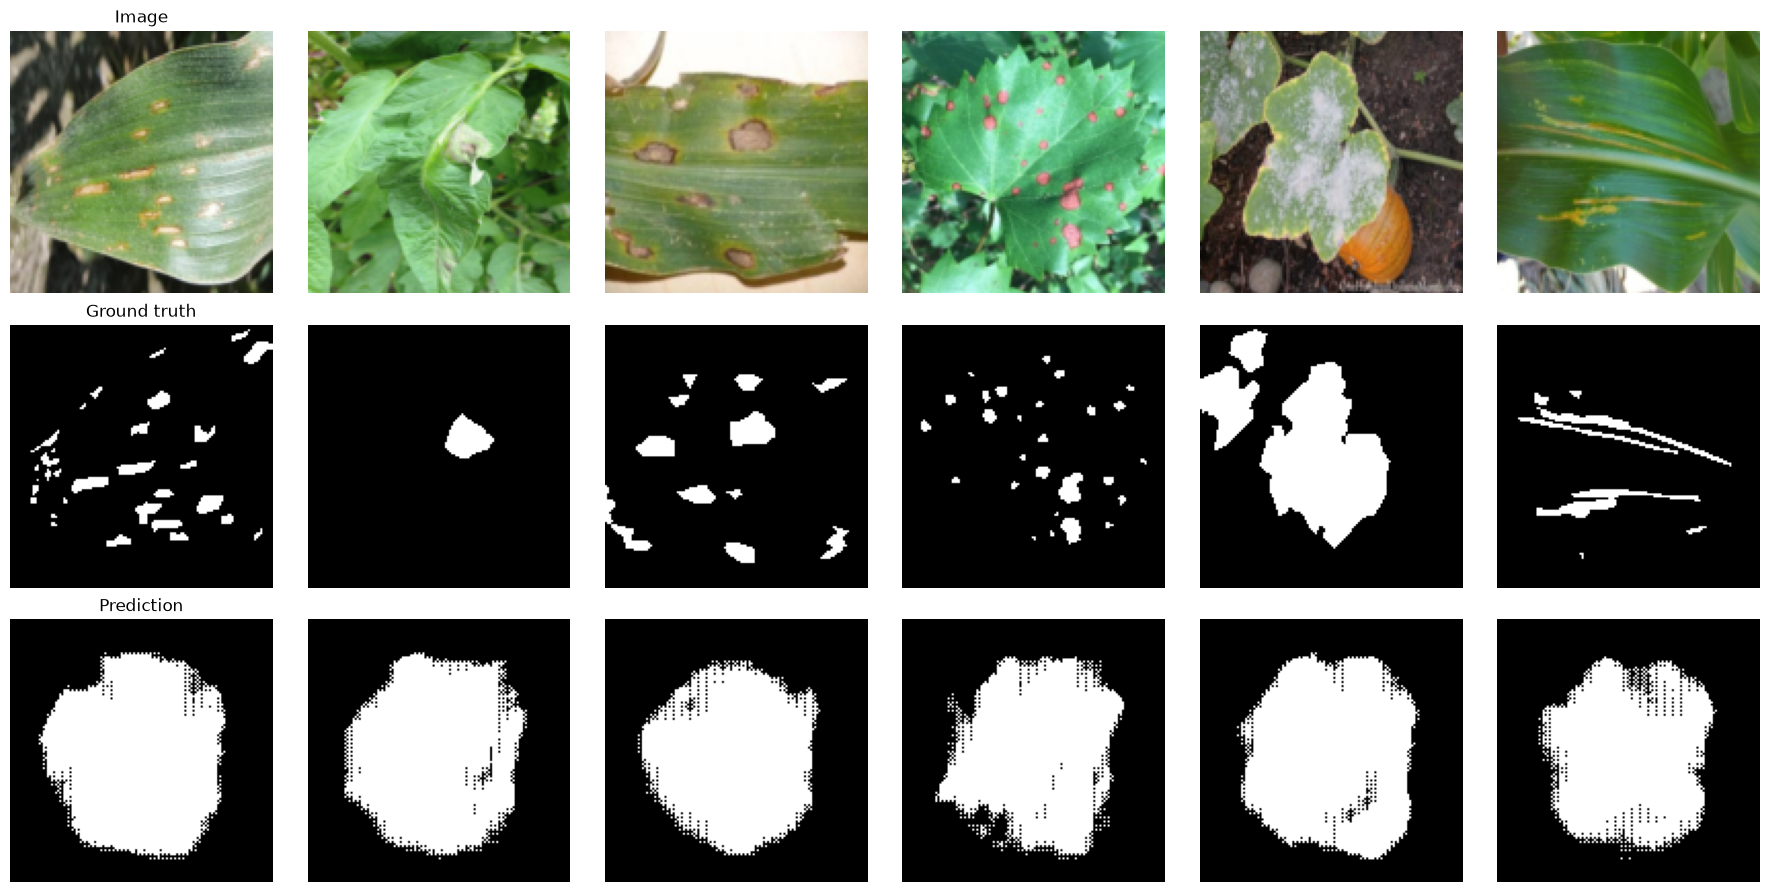

In [25]:
import matplotlib.pyplot as plt

for imgs, masks in test_ds_seg.take(1):
    preds = best_unet.predict(imgs)
    preds_bin = (preds > 0.5).astype(np.float32)

    fig, axes = plt.subplots(3, 6, figsize=(18, 9))
    for i in range(6):
        axes[0, i].imshow(imgs[i])
        axes[0, i].set_title("Image" if i == 0 else "")
        axes[0, i].axis("off")
        axes[1, i].imshow(masks[i, :, :, 0], cmap="gray")
        axes[1, i].set_title("Ground truth" if i == 0 else "")
        axes[1, i].axis("off")
        axes[2, i].imshow(preds_bin[i, :, :, 0], cmap="gray")
        axes[2, i].set_title("Prediction" if i == 0 else "")
        axes[2, i].axis("off")
    plt.tight_layout()
    plt.show()

In [26]:
for i in range(6):
    true_frac = masks[i, :, :, 0].numpy().mean()
    pred_frac = preds_bin[i, :, :, 0].mean()
    print(f"Image {i}: true diseased area = {true_frac:.3f}, predicted diseased area = {pred_frac:.3f}")

Image 0: true diseased area = 0.060, predicted diseased area = 0.411
Image 1: true diseased area = 0.020, predicted diseased area = 0.392
Image 2: true diseased area = 0.069, predicted diseased area = 0.356
Image 3: true diseased area = 0.033, predicted diseased area = 0.363
Image 4: true diseased area = 0.261, predicted diseased area = 0.402
Image 5: true diseased area = 0.053, predicted diseased area = 0.351


In [28]:
best_unet = tf.keras.models.load_model(
    checkpoint_path_v2,
    custom_objects={"bce_dice_loss": bce_dice_loss, "iou_metric": iou_metric}
)

encoder = best_unet.layers[1]  # the down_stack submodel — confirm this index with best_unet.summary() if it errors
encoder.trainable = True
fine_tune_at = len(encoder.layers) - 20  # unfreeze roughly the last 20 layers only
for layer in encoder.layers[:fine_tune_at]:
    layer.trainable = False

best_unet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=bce_dice_loss,
    metrics=[iou_metric]
)

finetune_checkpoint_path = "../models/unet_mobilenet_finetuned.keras"
history_unet_ft = best_unet.fit(
    train_ds_seg,
    validation_data=val_ds_seg,
    epochs=30,
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(finetune_checkpoint_path, save_best_only=True, monitor="val_iou_metric", mode="max"),
        tf.keras.callbacks.EarlyStopping(monitor="val_iou_metric", mode="max", patience=10, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_iou_metric", mode="max", factor=0.5, patience=5, min_lr=1e-7)
    ]
)

Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - iou_metric: 0.3135 - loss: 1.0182 - val_iou_metric: 0.2960 - val_loss: 1.1486 - learning_rate: 1.0000e-05
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - iou_metric: 0.3138 - loss: 1.0132 - val_iou_metric: 0.3127 - val_loss: 1.0810 - learning_rate: 1.0000e-05
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - iou_metric: 0.3165 - loss: 1.0075 - val_iou_metric: 0.3177 - val_loss: 1.0570 - learning_rate: 1.0000e-05
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - iou_metric: 0.3162 - loss: 1.0064 - val_iou_metric: 0.3218 - val_loss: 1.0489 - learning_rate: 1.0000e-05
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - iou_metric: 0.3151 - loss: 1.0103 - val_iou_metric: 0.3222 - val_loss: 1.0562 - learning_rate: 1.0000e-05
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - iou_metric: 0.3201 - loss: 1.0047 - val_iou_metric: 0.3266 - val_loss: 1.0465 - learning_rate: 1.0000e-05
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - 

In [30]:
print(dir())  # or just: sample_images

['Counter', 'IMG_DIR', 'IMG_SIZE', 'Image', 'In', 'MASK_DIR', 'OUT_IMG_DIR', 'OUT_MASK_DIR', 'Out', 'Path', 'SEG_IMG_DIR', 'SEG_MASK_DIR', 'TARGET_SIZE', '_', '__', '___', '__builtin__', '__builtins__', '__doc__', '__loader__', '__name__', '__package__', '__session__', '__spec__', '_dh', '_i', '_i1', '_i10', '_i11', '_i12', '_i13', '_i14', '_i15', '_i16', '_i17', '_i18', '_i19', '_i2', '_i20', '_i21', '_i22', '_i23', '_i24', '_i25', '_i26', '_i27', '_i28', '_i29', '_i3', '_i30', '_i4', '_i5', '_i6', '_i7', '_i8', '_i9', '_ih', '_ii', '_iii', '_oh', 'arr', 'augment_pair', 'axes', 'bce_dice_loss', 'best_unet', 'build_unet', 'build_unet_mobilenet', 'checkpoint_cb', 'checkpoint_cb2', 'checkpoint_path_local', 'checkpoint_path_v2', 'colors', 'conv_block', 'counts', 'dice_loss', 'diseased_fractions', 'diseased_fractions_all', 'early_stop_cb', 'early_stop_cb2', 'encoder', 'exit', 'fig', 'fine_tune_at', 'finetune_checkpoint_path', 'finetuned', 'get_ipython', 'history_unet', 'history_unet2', 'hi

In [31]:
preds_ft = finetuned.predict(np.array(imgs))
preds_ft_bin = (preds_ft > 0.5).astype(np.float32)

for i in range(6):
    true_frac = masks[i][:, :, 0].mean() if hasattr(masks[i], 'mean') else masks[i].numpy()[:, :, 0].mean()
    pred_frac = preds_ft_bin[i, :, :, 0].mean()
    print(f"Image {i}: true = {true_frac:.3f}, pred (fine-tuned) = {pred_frac:.3f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Image 0: true = 0.060, pred (fine-tuned) = 0.183
Image 1: true = 0.020, pred (fine-tuned) = 0.169
Image 2: true = 0.069, pred (fine-tuned) = 0.115
Image 3: true = 0.033, pred (fine-tuned) = 0.158
Image 4: true = 0.261, pred (fine-tuned) = 0.269
Image 5: true = 0.053, pred (fine-tuned) = 0.079


In [32]:
for i in range(6):
    true_frac = masks[i][:, :, 0].mean() if hasattr(masks[i], 'mean') else masks[i].numpy()[:, :, 0].mean()
    pred_before = preds_bin[i, :, :, 0].mean()
    pred_after = preds_ft_bin[i, :, :, 0].mean()
    print(f"Image {i}: true = {true_frac:.3f}, before = {pred_before:.3f}, after = {pred_after:.3f}")

Image 0: true = 0.060, before = 0.411, after = 0.183
Image 1: true = 0.020, before = 0.392, after = 0.169
Image 2: true = 0.069, before = 0.356, after = 0.115
Image 3: true = 0.033, before = 0.363, after = 0.158
Image 4: true = 0.261, before = 0.402, after = 0.269
Image 5: true = 0.053, before = 0.351, after = 0.079


In [34]:
from scipy.stats import spearmanr
rho, pval = spearmanr(true_fracs, pred_fracs)
print(f"Spearman rho={rho:.3f}, p={pval:.4f}")

Spearman rho=0.497, p=0.0000


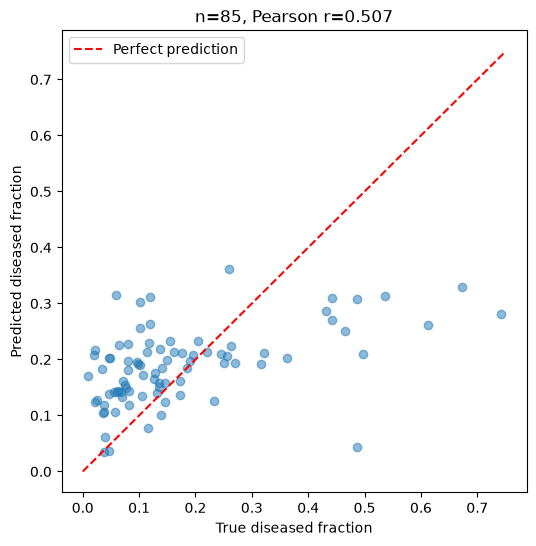

In [35]:
plt.figure(figsize=(6,6))
plt.scatter(true_fracs, pred_fracs, alpha=0.5)
plt.plot([0, 0.75], [0, 0.75], 'r--', label='Perfect prediction')
plt.xlabel('True diseased fraction')
plt.ylabel('Predicted diseased fraction')
plt.title(f'n={len(true_fracs)}, Pearson r={corr:.3f}')
plt.legend()
plt.show()

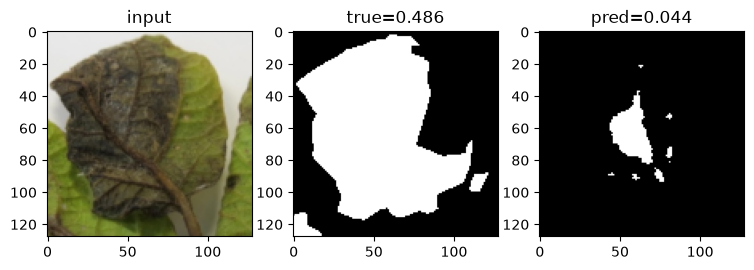

In [36]:
# rerun capturing the image itself so you can inspect the bad case
for images, masks_batch in val_ds_seg:
    preds_batch = (finetuned.predict(images, verbose=0) > 0.5).astype(np.float32)
    for i in range(images.shape[0]):
        t = masks_batch[i, :, :, 0].numpy().mean()
        p = preds_batch[i, :, :, 0].mean()
        if 0.4 < t < 0.6 and p < 0.15:
            plt.figure(figsize=(9,3))
            plt.subplot(1,3,1); plt.imshow(images[i]); plt.title(f"input")
            plt.subplot(1,3,2); plt.imshow(masks_batch[i,:,:,0], cmap='gray'); plt.title(f"true={t:.3f}")
            plt.subplot(1,3,3); plt.imshow(preds_batch[i,:,:,0], cmap='gray'); plt.title(f"pred={p:.3f}")
            plt.show()

In [37]:
import tensorflow as tf

# Classifier
classifier = tf.keras.models.load_model("../models/mobilenetv2_finetuned.keras")
classifier.export("../models/classifier_savedmodel")

# Severity U-Net (fine-tuned checkpoint from Stage 3)
severity_model = tf.keras.models.load_model(
    finetune_checkpoint_path,
    custom_objects={"bce_dice_loss": bce_dice_loss, "iou_metric": iou_metric}
)
severity_model.export("../models/severity_unet_savedmodel")

INFO:tensorflow:Assets written to: ../models/classifier_savedmodel\assets


INFO:tensorflow:Assets written to: ../models/classifier_savedmodel\assets


Saved artifact at '../models/classifier_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 38), dtype=tf.float32, name=None)
Captures:
  2377918704208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379208936144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379208938448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379208935376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379208938640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379208935568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379208937296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379208936720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379208937872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379208936912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379208939792: Te

INFO:tensorflow:Assets written to: ../models/severity_unet_savedmodel\assets


Saved artifact at '../models/severity_unet_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='input_layer_4')
Output Type:
  TensorSpec(shape=(None, 128, 128, 1), dtype=tf.float32, name=None)
Captures:
  2379813782544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379813797136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379813797328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379813797712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379813796752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379813782160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379813796944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379813795216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379813781584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2379813795792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  23798

In [42]:
inputs = classifier.input

x = classifier.get_layer("mobilenetv2_1.00_224")(inputs, training=False)
x = classifier.get_layer("global_average_pooling2d")(x)
x = classifier.get_layer("dropout")(x, training=False)
outputs = classifier.get_layer("dense")(x)

inference_model = tf.keras.Model(inputs=inputs, outputs=outputs, name="classifier_inference")

In [44]:
p1 = classifier.predict(test_img, verbose=0)
p2 = classifier.predict(test_img, verbose=0)
print("Run-to-run difference on ORIGINAL classifier:", np.max(np.abs(p1 - p2)))

Run-to-run difference on ORIGINAL classifier: 0.0


In [45]:
data_aug = classifier.get_layer("data_augmentation")
aug_out = data_aug(test_img, training=False)

print("data_augmentation output vs raw input, max diff:", np.max(np.abs(aug_out.numpy() - test_img)))

data_augmentation output vs raw input, max diff: 0.0


In [47]:
x = classifier.get_layer("data_augmentation")(test_img, training=False)
x = classifier.get_layer("mobilenetv2_1.00_224")(x, training=False)
x = classifier.get_layer("global_average_pooling2d")(x)
x = classifier.get_layer("dropout")(x, training=False)
manual_with_aug = classifier.get_layer("dense")(x).numpy()

orig_pred = classifier.predict(test_img, verbose=0)
print("Manual chain (incl. data_aug) vs classifier.predict():", np.max(np.abs(manual_with_aug - orig_pred)))

Manual chain (incl. data_aug) vs classifier.predict(): 0.9718447


In [49]:
x_true = classifier.get_layer("data_augmentation")(test_img, training=True)
x_true = classifier.get_layer("mobilenetv2_1.00_224")(x_true, training=True)
x_true = classifier.get_layer("global_average_pooling2d")(x_true)
x_true = classifier.get_layer("dropout")(x_true, training=True)
manual_with_training_true = classifier.get_layer("dense")(x_true).numpy()

orig_pred = classifier.predict(test_img, verbose=0)
print("Manual chain (training=True) vs classifier.predict():", np.max(np.abs(manual_with_training_true - orig_pred)))

Manual chain (training=True) vs classifier.predict(): 0.94398326
